In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import BaggingClassifier, GradientBoostingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    f1_score, accuracy_score,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc,
    precision_recall_curve, average_precision_score
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import clone
from sklearn.pipeline import Pipeline

In [2]:
df = pd.read_csv('data.csv')
df.head()

,process.b1.capacity,process.b2.capacity,process.b3.capacity,process.b4.capacity,property.price,property.product,property.winner,verification.result,verification.time
0,0,0,2,1,59,1,0,False,163.316667
1,0,0,2,1,59,2,0,False,200.860000
2,0,0,2,1,59,4,0,False,154.888889
3,0,0,2,1,59,6,0,False,108.640000
4,0,0,2,1,60,1,0,True,85.466667


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2043 entries, 0 to 2042
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   process.b1.capacity  2043 non-null   int64  
 1   process.b2.capacity  2043 non-null   int64  
 2   process.b3.capacity  2043 non-null   int64  
 3   process.b4.capacity  2043 non-null   int64  
 4   property.price       2043 non-null   int64  
 5   property.product     2043 non-null   int64  
 6   property.winner      2043 non-null   int64  
 7   verification.result  2043 non-null   bool   
 8   verification.time    2043 non-null   float64
dtypes: bool(1), float64(1), int64(7)
memory usage: 129.8 KB


In [4]:
df.isna().sum()

process.b1.capacity    0
process.b2.capacity    0
process.b3.capacity    0
process.b4.capacity    0
property.price         0
property.product       0
property.winner        0
verification.result    0
verification.time      0
dtype: int64

In [5]:
# Проверяем полные дубликаты
df.duplicated().sum()

np.int64(0)

In [6]:
# Проверяем распределение целевых классов
df['verification.result'].value_counts()

verification.result
False    1781
True      262
Name: count, dtype: int64

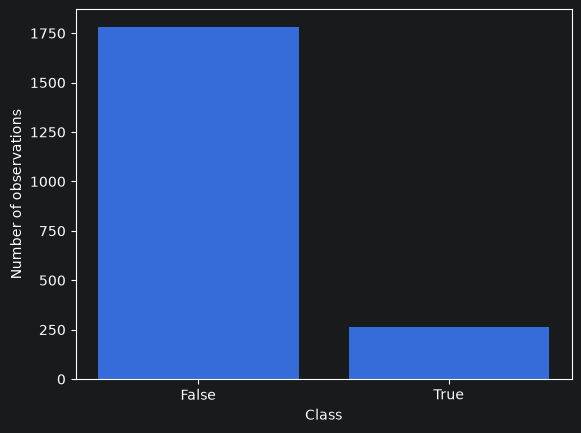

In [7]:
# Наблюдаю сильный дисбаланс, false - 87.2%, true - 12.8%. Визуализируем дисбаланс
class_counts = df['verification.result'].value_counts()
plt.bar(class_counts.index.astype(str), class_counts.values)
plt.xlabel('Class')
plt.ylabel('Number of observations')
plt.show()

In [8]:
# Ничего аномального не заметил
df.describe()

,process.b1.capacity,process.b2.capacity,process.b3.capacity,process.b4.capacity,property.price,property.product,property.winner,verification.time
count,2043.000000,2043.000000,2043.000000,2043.000000,2043.000000,2043.000000,2043.000000,2043.000000
mean,1.000000,2.093979,1.883994,0.587861,71.473324,3.252080,0.455213,7336.944574
std,0.816696,0.811269,0.320310,0.492340,8.048740,1.804225,1.062828,10375.393650
min,0.000000,0.000000,1.000000,0.000000,59.000000,1.000000,0.000000,77.916667
25%,0.000000,1.000000,2.000000,0.000000,65.000000,2.000000,0.000000,546.818910
50%,1.000000,2.000000,2.000000,1.000000,70.000000,3.000000,0.000000,1316.983333
75%,2.000000,3.000000,2.000000,1.000000,78.000000,5.000000,0.000000,10876.638889
max,2.000000,3.000000,2.000000,1.000000,90.000000,6.000000,4.000000,44130.520833


In [9]:
# Проверяем частоты категорий и значений вместимости четвёртого участника
df['property.winner'].value_counts().sort_index()

property.winner
0    1680
1      58
2     114
3     120
4      71
Name: count, dtype: int64

In [10]:
df['process.b4.capacity'].value_counts().sort_index()

process.b4.capacity
0     842
1    1201
Name: count, dtype: int64

In [11]:
# Ничего криминального не вижу, делим датасет, 60/20/20
# Исключаем целевой класс и время проверки из входных признаков
x = df.drop(columns=['verification.result', 'verification.time'])
y = df['verification.result']

x_train_val, x_test, y_train_val, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

x_train, x_val, y_train, y_val = train_test_split(
    x_train_val,
    y_train_val,
    test_size=0.25,
    random_state=42,
    stratify=y_train_val
)

print(x_train.shape, x_val.shape, x_test.shape)

(1225, 7) (409, 7) (409, 7)


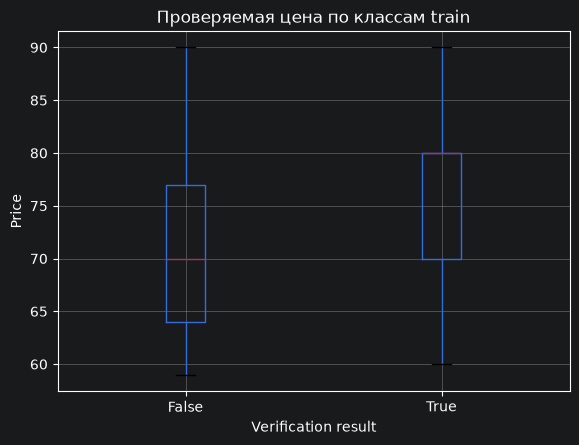

In [12]:
# Создаём таблицу для анализа только тренировочной выборки
train_analysis = x_train.copy()
train_analysis['verification.result'] = y_train

# Сравниваем проверяемую цену между классами
train_analysis.boxplot(column='property.price', by='verification.result')
plt.xlabel('Verification result')
plt.ylabel('Price')
plt.title('Проверяемая цена по классам train')
plt.suptitle('')
plt.show()

In [13]:
# У класса True медиана цены около 80, у false 70. Сделаем две фичи
# total_capacity - сумма вместимости 4-ых участников
# active_bidders - число участников, вместимость которых больше нуля
capacity_cols = [
    'process.b1.capacity',
    'process.b2.capacity',
    'process.b3.capacity',
    'process.b4.capacity'
]
total_capacity = x_train[capacity_cols].sum(axis=1)
active_bidders = (x_train[capacity_cols] > 0).sum(axis=1)

x_train['total_capacity'] = total_capacity
x_train['active_bidders'] = active_bidders

total_capacity_val = x_val[capacity_cols].sum(axis=1)
active_bidders_val = (x_val[capacity_cols] > 0).sum(axis=1)

x_val['total_capacity'] = total_capacity_val
x_val['active_bidders'] = active_bidders_val

total_capacity_test = x_test[capacity_cols].sum(axis=1)
active_bidders_test = (x_test[capacity_cols] > 0).sum(axis=1)

x_test['total_capacity'] = total_capacity_test
x_test['active_bidders'] = active_bidders_test

In [14]:
# Разделяем категориальные и числовые фичи
categorical_cols = ['property.product', 'property.winner']
numeric_cols = x_train.columns.difference(categorical_cols)

In [15]:
# Кодируем категориальные фичи
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
cat_train_encoded = encoder.fit_transform(x_train[categorical_cols])
cat_val_encoded = encoder.transform(x_val[categorical_cols])
cat_test_encoded = encoder.transform(x_test[categorical_cols])

In [16]:
# Масштабируем фичи, обучаем только на train
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train[numeric_cols])
x_val_scaled = scaler.transform(x_val[numeric_cols])
x_test_scaled = scaler.transform(x_test[numeric_cols])

In [17]:
# Объединяем масштабированные фичи и закодированные категориальные числа
x_train_ready = np.hstack((x_train_scaled, cat_train_encoded))
x_val_ready = np.hstack((x_val_scaled, cat_val_encoded))
x_test_ready = np.hstack((x_test_scaled, cat_test_encoded))

In [18]:
# Обучаем базовый беггинг и сравниваем качество на train и validation
bag_model = BaggingClassifier(random_state=42)
bag_model.fit(x_train_ready, y_train)

y_val_pred = bag_model.predict(x_val_ready)
y_train_pred = bag_model.predict(x_train_ready)

# Accuracy valid and train
bag_accuracy_val = accuracy_score(y_val, y_val_pred)
bag_accuracy_train = accuracy_score(y_train, y_train_pred)

# F1 score valid and train
bag_f1_val = f1_score(y_val, y_val_pred, average='macro')
bag_f1_train = f1_score(y_train, y_train_pred, average='macro')

print(f'{bag_accuracy_val}, {bag_f1_val} \n{bag_accuracy_train}, {bag_f1_train}')

0.9828850855745721, 0.9611243125806233 
1.0, 1.0


In [19]:
# Обучаем базовый бустинг и сравниваем качество на train и validation
boost_model = GradientBoostingClassifier(random_state=42)
boost_model.fit(x_train_ready, y_train)

y_val_pred = boost_model.predict(x_val_ready)
y_train_pred = boost_model.predict(x_train_ready)

# Accuracy valid and train
boost_accuracy_val = accuracy_score(y_val, y_val_pred)
boost_accuracy_train = accuracy_score(y_train, y_train_pred)

# F1 score valid and train
boost_f1_val = f1_score(y_val, y_val_pred, average='macro')
boost_f1_train = f1_score(y_train, y_train_pred, average='macro')

print(f'{boost_accuracy_val}, {boost_f1_val} \n{boost_accuracy_train}, {boost_f1_train}')

0.9853300733496333, 0.9663982911600395 
0.9951020408163266, 0.9889814348420523


In [20]:
# Задаем подготовку числовых и категориальных фич для стекинга
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_cols),
    ('cat', OneHotEncoder(sparse_output=False, handle_unknown='ignore'),
     categorical_cols),
])

In [21]:
# Создаем базовые модели с независимой подготовкой даты
estimators = [
    ('tree', Pipeline([
        ('prep', clone(preprocessor)),
        ('model', DecisionTreeClassifier(random_state=42)),
    ])),
    ('log', Pipeline([
        ('prep', clone(preprocessor)),
        ('model', LogisticRegression()),
    ]))
]

In [22]:
# Обучаем базовый стекинг
stack_model = StackingClassifier(estimators=estimators)
stack_model.fit(x_train, y_train)

,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.The type of estimator is generally expected to be a classifier.However, one can pass a regressor for some use case (e.g. ordinalregression).","[('tree', ...), ('log', ...)]"
,"final_estimator final_estimator: estimator, default=NoneA classifier which will be used to combine the base estimators.The default classifier is a:class:`~sklearn.linear_model.LogisticRegression`.",None
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",None
,"stack_method stack_method: {'auto', 'predict_proba', 'decision_function', 'predict'}, default='auto'Methods called for each base estimator. It can be:* if 'auto', it will try to invoke, for each estimator, `'predict_proba'`, `'decision_function'` or `'predict'` in that order.* otherwise, one of `'predict_proba'`, `'decision_function'` or `'predict'`. If the method is not implemented by the estimator, it will raise an error.",'auto'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary <n_jobs>` for more details.",None
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",False
,"verbose verbose: int, default=0Verbosity level.",0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,) or list of ndarray if `y` is of type `""multilabel-indicator""`.Class labels.","ndarray[bool](2,)","[False, True]"
"estimators_ estimators_: list of estimatorsThe elements of the `estimators` parameter, having been fitted on thetraining data. If an estimator has been set to `'drop'`, itwill not appear in `estimators_`. When `cv=""prefit""`, `estimators_`is set to `estimators` and is not fitted again.",list,"[Pipeline(step...m_state=42))]), Pipeline(step...egression())])]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['process.b1.capaci

In [23]:
# Получаем прогнозы стекинга на train и validation и вычисляем f1 macro и accuracy
stack_train_pred = stack_model.predict(x_train)
stack_val_pred = stack_model.predict(x_val)

# Accuracy valid and train
stack_accuracy_val = accuracy_score(y_val, stack_val_pred)
stack_accuracy_train = accuracy_score(y_train, stack_train_pred)

# F1 macro valid and train
stack_f1_val = f1_score(y_val, stack_val_pred, average='macro')
stack_f1_train = f1_score(y_train, stack_train_pred, average='macro')

print(f'{stack_accuracy_val}, {stack_f1_val} \n{stack_accuracy_train}, {stack_f1_train}')

0.9828850855745721, 0.9604650841653204 
1.0, 1.0


In [24]:
# Подбираем число деревьев n_estimators
n_values = [10, 30, 50, 100, 200]
bag_results = []

for n in n_values:
    bag_model = BaggingClassifier(n_estimators=n, random_state=42)
    bag_model.fit(x_train_ready, y_train)

    y_val_pred = bag_model.predict(x_val_ready)

    # F1 macro valid
    bag_f1_pre = f1_score(y_val, y_val_pred, average='macro')

    bag_results.append({'n_estimators': n, 'f1_score': bag_f1_pre})

bag_results_df = pd.DataFrame(bag_results)
bag_results_df

,n_estimators,f1_score
0,10,0.961124
1,30,0.961124
2,50,0.955198
3,100,0.954429
4,200,0.954429


In [25]:
# Обучаем беггинг с лучшим гиперпараметром
best_index = bag_results_df['f1_score'].idxmax()
best_n = int(bag_results_df.loc[best_index, 'n_estimators'])

best_bag = BaggingClassifier(n_estimators=best_n, random_state=42)
best_bag.fit(x_train_ready, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random resampling of the original dataset(sample wise and feature wise).If the base estimator accepts a `random_state` attribute, a differentseed is generated for each instance in the ensemble.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"estimator estimator: object, default=NoneThe base estimator to fit on random subsets of the dataset.If None, then the base estimator is a:class:`~sklearn.tree.DecisionTreeClassifier`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"n_estimators n_estimators: int, default=10The number of base estimators in the ensemble.",10
,"max_samples max_samples: int or float, default=NoneThe number of samples to draw from X to train each base estimator (withreplacement by default, see `bootstrap` for more details).- If None, then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples.",None
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator (without replacement by default, see `bootstrap_features` for moredetails).- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.",1.0
,"bootstrap bootstrap: bool, default=TrueWhether samples are drawn with replacement. If False, sampling withoutreplacement is performed. If fitting with `sample_weight`, it isstrongly recommended to choose True, as only drawing with replacementwill ensure the expected frequency semantics of `sample_weight`.",True
,"bootstrap_features bootstrap_features: bool, default=FalseWhether features are drawn with replacement.",False
,"oob_score oob_score: bool, default=FalseWhether to use out-of-bag samples to estimatethe generalization error. Only available if bootstrap=True.",False
,"warm_start warm_start: bool, default=FalseWhen set to True, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fita whole new ensemble. See :term:`the Glossary <warm_start>`... versionadded:: 0.17 *warm_start* constructor parameter.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for both :meth:`fit` and:meth:`predict`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity when fitting and predicting.",0


In [26]:
# Подбираем число деревьев и скорость обучения бустинга
n_values = [50, 100, 200]
learning_rates = [0.05, 0.1, 0.2]
boost_results = []

for n in n_values:
    for lr in learning_rates:
        model = GradientBoostingClassifier(
            n_estimators=n,
            learning_rate=lr,
            random_state=42
        )
        model.fit(x_train_ready, y_train)

        y_val_pred = model.predict(x_val_ready)

        # F1 macro valid
        boost_f1_pre = f1_score(y_val, y_val_pred, average='macro')

        boost_results.append({'n_estimators': n, 'learning_rate': lr, 'f1_score': boost_f1_pre})

boost_results_df = pd.DataFrame(boost_results)
boost_results_df

,n_estimators,learning_rate,f1_score
0,50,0.05,0.828718
1,50,0.10,0.902024
2,50,0.20,0.977599
3,100,0.05,0.902024
4,100,0.10,0.966398
5,100,0.20,0.977599
6,200,0.05,0.972232
7,200,0.10,0.977599
8,200,0.20,0.977599


In [27]:
# Выбираем параметры по максимальному F1 macro на валидации
best_index = boost_results_df['f1_score'].idxmax()
best_n_boost = int(boost_results_df.loc[best_index, 'n_estimators'])
best_lr = boost_results_df.loc[best_index, 'learning_rate']

best_boost = GradientBoostingClassifier(
    n_estimators=best_n_boost,
    learning_rate=best_lr,
    random_state=42
)
best_boost.fit(x_train_ready, y_train)

,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",np.float64(0.2)
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",50
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_

In [28]:
# Подбираем регуляризацию итоговой модели стекинга
C_values = [0.01, 0.1, 1, 10, 100]
stack_results = []

for C in C_values:
    model = StackingClassifier(
        estimators=estimators,
        final_estimator=LogisticRegression(C=C)
    )
    model.fit(x_train, y_train)

    y_val_pred = model.predict(x_val)

    # F1 macro valid
    stack_f1_pre = f1_score(y_val, y_val_pred, average='macro')

    stack_results.append({'C': C, 'f1_score': stack_f1_pre})

stack_results_df = pd.DataFrame(stack_results)
stack_results_df

,C,f1_score
0,0.01,0.465359
1,0.10,0.960465
2,1.00,0.960465
3,10.00,0.960465
4,100.00,0.960465


In [29]:
# Выбираем C и обучаем итоговый стекинг
best_index = stack_results_df['f1_score'].idxmax()
best_C = stack_results_df.loc[best_index, 'C']

best_stack = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(C=best_C)
)
best_stack.fit(x_train, y_train)

,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.The type of estimator is generally expected to be a classifier.However, one can pass a regressor for some use case (e.g. ordinalregression).","[('tree', ...), ('log', ...)]"
,"final_estimator final_estimator: estimator, default=NoneA classifier which will be used to combine the base estimators.The default classifier is a:class:`~sklearn.linear_model.LogisticRegression`.",LogisticRegre....float64(0.1))
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",None
,"stack_method stack_method: {'auto', 'predict_proba', 'decision_function', 'predict'}, default='auto'Methods called for each base estimator. It can be:* if 'auto', it will try to invoke, for each estimator, `'predict_proba'`, `'decision_function'` or `'predict'` in that order.* otherwise, one of `'predict_proba'`, `'decision_function'` or `'predict'`. If the method is not implemented by the estimator, it will raise an error.",'auto'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary <n_jobs>` for more details.",None
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",False
,"verbose verbose: int, default=0Verbosity level.",0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,) or list of ndarray if `y` is of type `""multilabel-indicator""`.Class labels.","ndarray[bool](2,)","[False, True]"
"estimators_ estimators_: list of estimatorsThe elements of the `estimators` parameter, having been fitted on thetraining data. If an estimator has been set to `'drop'`, itwill not appear in `estimators_`. When `cv=""prefit""`, `estimators_`is set to `estimators` and is not fitted again.",list,"[Pipeline(step...m_state=42))]), Pipeline(step...egression())])]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[object]

In [30]:
# Оцениваем выбранные модели на тестовой выборке
bag_test_pred = best_bag.predict(x_test_ready)
boost_test_pred = best_boost.predict(x_test_ready)
stack_test_pred = best_stack.predict(x_test)

# Accuracy
bag_accuracy_test = accuracy_score(y_test, bag_test_pred)
boost_accuracy_test = accuracy_score(y_test, boost_test_pred)
stack_accuracy_test = accuracy_score(y_test, stack_test_pred)

# F1 score
bag_f1_test = f1_score(y_test, bag_test_pred, average='macro')
boost_f1_test = f1_score(y_test, boost_test_pred, average='macro')
stack_f1_test = f1_score(y_test, stack_test_pred, average='macro')

comparison = pd.DataFrame({
    'Model': ['Bagging', 'Boosting', 'Stacking'],
    'Accuracy': [bag_accuracy_test, boost_accuracy_test, stack_accuracy_test],
    'F1 macro': [bag_f1_test, boost_f1_test, stack_f1_test]
})

comparison

,Model,Accuracy,F1 macro
0,Bagging,0.982885,0.961124
1,Boosting,0.997555,0.994446
2,Stacking,0.987775,0.971270


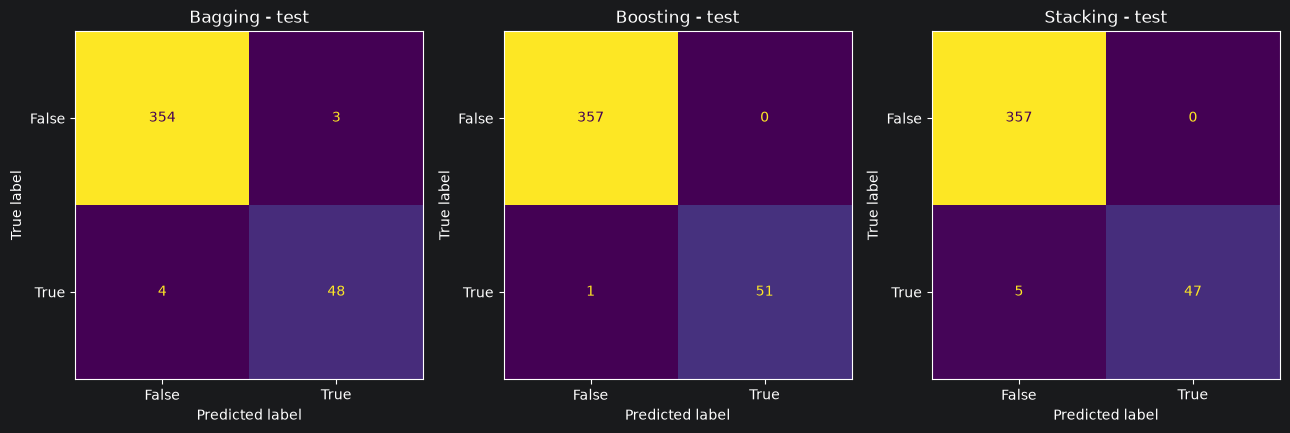

In [31]:
# Строим матрицы ошибок трех моделей на тестовой выборке
labels = [False, True]
fig, ax = plt.subplots(1, 3, figsize=(13, 6))

disp_bag = ConfusionMatrixDisplay(confusion_matrix(y_test, bag_test_pred, labels=labels), display_labels=labels)
disp_bag.plot(ax=ax[0], colorbar=False)
disp_boost = ConfusionMatrixDisplay(confusion_matrix(y_test, boost_test_pred, labels=labels), display_labels=labels)
disp_boost.plot(ax=ax[1], colorbar=False)
disp_stack = ConfusionMatrixDisplay(confusion_matrix(y_test, stack_test_pred, labels=labels), display_labels=labels)
disp_stack.plot(ax=ax[2], colorbar=False)

ax[0].set_title('Bagging - test')
ax[1].set_title('Boosting - test')
ax[2].set_title('Stacking - test')
plt.tight_layout()
plt.show()

In [32]:
# Получаем вероятности
bag_proba = best_bag.predict_proba(x_test_ready)
boost_proba = best_boost.predict_proba(x_test_ready)
stack_proba = best_stack.predict_proba(x_test)

In [33]:
# Вычисляем ROC и AUC для положительного класса True
fpr_bag, tpr_bag, _ = roc_curve(y_test, bag_proba[:, 1])
auc_bag = auc(fpr_bag, tpr_bag)

fpr_boost, tpr_boost, _ = roc_curve(y_test, boost_proba[:, 1])
auc_boost = auc(fpr_boost, tpr_boost)

fpr_stack, tpr_stack, _ = roc_curve(y_test, stack_proba[:, 1])
auc_stack = auc(fpr_stack, tpr_stack)

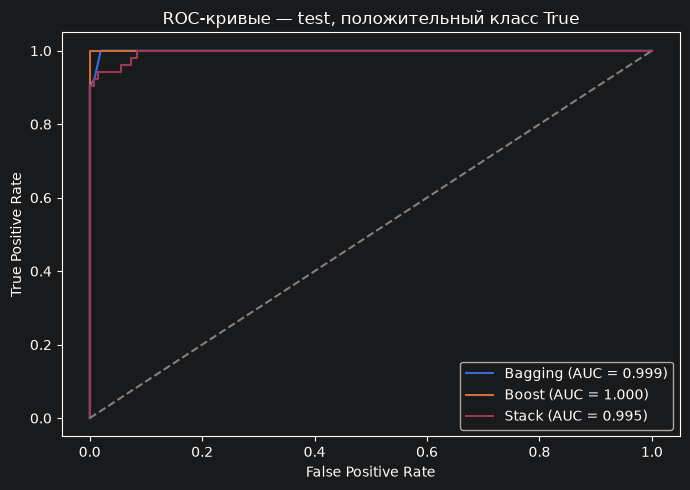

In [34]:
# Сравниваем ROC кривые моделей на тесте
plt.figure(figsize=(7, 5))

plt.plot(fpr_bag, tpr_bag, label=f'Bagging (AUC = {auc_bag:.3f})')
plt.plot(fpr_boost, tpr_boost, label=f'Boost (AUC = {auc_boost:.3f})')
plt.plot(fpr_stack, tpr_stack, label=f'Stack (AUC = {auc_stack:.3f})')

plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривые — test, положительный класс True')
plt.legend()
plt.tight_layout()
plt.show()

In [35]:
# Вычисляем precision, recall и Average Precision для класса True
precision_bag, recall_bag, _ = precision_recall_curve(y_test, bag_proba[:, 1])
ap_bag = average_precision_score(y_test, bag_proba[:, 1])

precision_boost, recall_boost, _ = precision_recall_curve(y_test, boost_proba[:, 1])
ap_boost = average_precision_score(y_test, boost_proba[:, 1])

precision_stack, recall_stack, _ = precision_recall_curve(y_test, stack_proba[:, 1])
ap_stack = average_precision_score(y_test, stack_proba[:, 1])

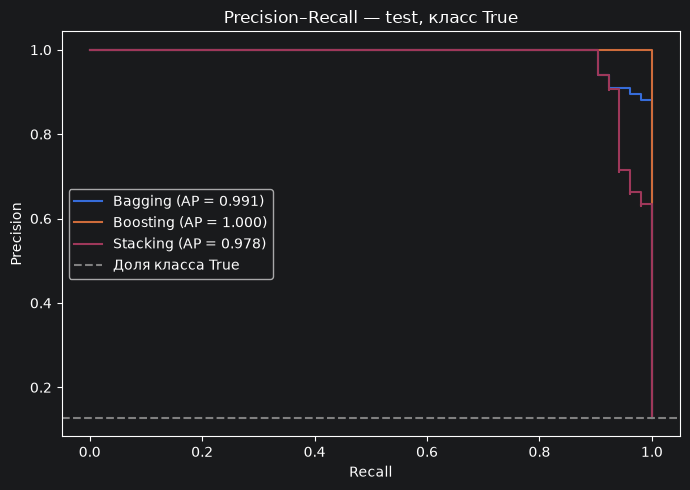

In [36]:
# Сравниваем Precision–Recall кривые на тестовой выборке
plt.figure(figsize=(7, 5))

plt.step(recall_bag, precision_bag, where='post',
         label=f'Bagging (AP = {ap_bag:.3f})')
plt.step(recall_boost, precision_boost, where='post',
         label=f'Boosting (AP = {ap_boost:.3f})')
plt.step(recall_stack, precision_stack, where='post',
         label=f'Stacking (AP = {ap_stack:.3f})')

plt.axhline(y_test.mean(), linestyle='--', color='gray',
            label='Доля класса True')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision–Recall — test, класс True')
plt.legend()
plt.tight_layout()
plt.show()

На данном тестовом разбиении лучший результат показал бустинг с 50 деревьями и learning_rate=0.2: accuracy = 0,9976, F1 macro = 0,9944. Модель допустила одну ошибку из 409 наблюдений. ROC и PR кривые также показали преимущество бустинга среди трёх рассмотренных ансамблей